# 10.3: Is it just spring? (Google Trends)

**Issue #10, cycle 2: The hemline index** (Pillar 5, Trend Forecast, With Receipts)

## What this notebook does

Two popular readings of skirts as economic signals both came in spring:

- **20 March 2025:** maxi skirt popularity up 393% over one week, read as a sign of a
  coming recession (Data, But Make It Fashion).
- **11 April 2026:** miniskirt popularity up 78% in April compared with the previous
  six months, read as a sign the economy was doing well (Data, But Make It Fashion).

This notebook asks: were those spring rises unusual, or does skirt interest rise
every spring regardless of the economy?

1. **Miniskirts, April vs. the previous six months:** her comparison, repeated for
   every year since 2005, to see whether April 2026 stands out.
2. **Maxi skirts, week-on-week:** week-on-week changes around mid-March 2025,
   compared with the same weeks in other years, matching her one-week window.
3. **The shape of a typical year:** average interest by month for both terms.

## Data

Google Trends, US, via `trendspy`.

| Pull | Terms | Timeframe | Resolution |
|---|---|---|---|
| Monthly | "maxi skirt", "mini skirt" | All available (2004 to now) | Monthly |
| Weekly | "maxi skirt", "mini skirt" | 2022 to 2025 | Weekly |

## Limitations

- **Related test, not a replication.** Her figures combine online posts and their
  sentiment, Google search and Pinterest search. This notebook uses Google search
  only, so it tests one part of her method, not all of it.
- **Searches are not what people wear.** Google Trends measures interest in a
  search term, not what people buy or wear.
- **Scores are relative.** Google scales each pull from 0 to 100, with 100 being
  the busiest point in that pull. Values can only be compared within the same pull,
  not across pulls. Both terms are pulled together so they share one scale.
- **Google samples its data.** Repeating a pull can give slightly different values.
  The saved CSVs are the record for this issue, with the pull date logged.
- **Search wording.** Only "maxi skirt" and "mini skirt" are used. Other spellings
  ("miniskirt") and related searches are not included.
- **US only**, to match her S&P 500 framing. Her own posts don't state a region.
- **Rounding.** Google reports whole numbers. In the 22-year monthly pull, recent
  values are only 10 to 17, so one point of rounding is a large percentage. Short-window
  comparisons use the weekly pull, which has its own finer scale; the monthly pull is
  used only for the long-run shape of a typical year.
- **April 2026 anomaly.** In the week of 12 April 2026, Google search interest peaked
  for "maxi skirt", "mini skirt", "skirt", "jeans" and "sofa" at the same time, with
  the same shape, while "pizza" stayed flat. A spike across unrelated shopping searches
  suggests a change in Google's data rather than real interest in skirts. April and
  May 2026 are excluded from conclusions about skirt length; the anomaly itself is
  reported as a finding.

## Outputs

- `data/raw/cycle 2/issue-10/trends_monthly.csv`
- `data/raw/cycle 2/issue-10/trends_weekly.csv`
- Exploratory charts only. Branded versions are made in Canva.
- Findings (section 4) feed slides 3 (THE STAT) and 6 (THE MECHANISM).

## 1. Setup

Imports and file paths. The notebook sits three folders below the repo root, so every
path starts with `../../../`. No API key is needed for Google Trends.

In [1]:
# Force the inline backend first, to avoid the Agg backend conflict hit in Issue #4
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")

import json
import time
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from trendspy import Trends

# Paths for this issue
RAW_DIR = Path("../../../data/raw/cycle 2/issue-10")
PROCESSED_DIR = Path("../../../data/processed/cycle 2/issue-10")
PALETTE_PATH = Path("../../../brand/palette.json")

for folder in (RAW_DIR, PROCESSED_DIR):
    assert folder.exists(), f"Missing folder: {folder}"

# Logged with every pull, because Google Trends values shift slightly between pulls
PULL_DATE = date.today().isoformat()
print(f"Pull date: {PULL_DATE}")

Pull date: 2026-10-16


## 2. Extracting data from Google Trends

### 2.1 Pull helper

One function pulls search interest for a list of terms and returns a clean table:
- The date becomes an ordinary column called `date`.
- Rows Google marks as partial (the current, unfinished period) are dropped, since
  an incomplete month or week would understate interest.
- Google limits how often it can be queried. If a pull fails (often a "429 Too Many
  Requests" error), the helper waits a minute and tries again, up to three times.

In [4]:
tr = Trends(request_delay=2.0)  # slower requests, to avoid Google's rate limit
TERMS = ["maxi skirt", "mini skirt"]

def pull_trends(keywords, timeframe, geo="US"):
    """Pull Google Trends interest over time as a clean DataFrame with a 'date' column."""
    for attempt in range(3):
        try:
            df = tr.interest_over_time(keywords, timeframe=timeframe, geo=geo)
            break
        except Exception as e:
            print(f"Attempt {attempt + 1} failed: {e}")
            time.sleep(60)
    else:
        raise RuntimeError("Google Trends pull failed three times. Try again later.")

    # Move the date out of the index into a column named 'date'
    df = df.reset_index()
    df = df.rename(columns={df.columns[0]: "date"})
    df["date"] = pd.to_datetime(df["date"])

    # Drop unfinished periods, if Google flags any
    if "isPartial" in df.columns:
        partial = df["isPartial"].astype(bool)
        print(f"Dropping {partial.sum()} partial row(s)")
        df = df.loc[~partial].drop(columns="isPartial")

    return df.reset_index(drop=True)

### 2.2 Monthly pull, 2004 to now

Both terms in one pull, so they share the same 0 to 100 scale. Over this long a
timeframe, Google returns one value per month.

In [5]:
monthly = pull_trends(TERMS, timeframe="all")
monthly["pull_date"] = PULL_DATE
monthly.to_csv(RAW_DIR / "trends_monthly.csv", index=False)

print(monthly.columns.tolist())
print(f"{monthly['date'].min().date()} to {monthly['date'].max().date()}, {len(monthly)} rows")
print(monthly.head(3).to_string(index=False))
print(monthly.tail(3).to_string(index=False))

Dropping 1 partial row(s)
['date', 'maxi skirt', 'mini skirt', 'pull_date']
2004-01-01 to 2026-09-01, 273 rows
      date  maxi skirt  mini skirt  pull_date
2004-01-01           0           4 2026-10-16
2004-02-01           0           5 2026-10-16
2004-03-01           1           5 2026-10-16
      date  maxi skirt  mini skirt  pull_date
2026-07-01          11          14 2026-10-16
2026-08-01          10          14 2026-10-16
2026-09-01          11          17 2026-10-16


### 2.3 Weekly pull, January 2022 to September 2026

Just under five years of weekly data, short enough for Google to return one value per
week. This covers five springs, including March 2025 and April 2026, plus the six
months before April 2026 that her comparison uses. Because this pull has its own 0 to
100 scale, recent values are larger and more precise than in the 22-year monthly pull.

In [7]:
# Pull each term on its own, so each gets its own 0-100 scale (finer values).
# The weekly tests only compare a term with itself, so a shared scale isn't needed.
weekly_parts = []
for term in TERMS:
    time.sleep(60)  # long pause between pulls, to stay under Google's rate limit
    df = pull_trends([term], timeframe="2022-01-01 2026-09-30")
    weekly_parts.append(df.set_index("date")[[term]])

weekly = pd.concat(weekly_parts, axis=1).reset_index()
weekly["pull_date"] = PULL_DATE
weekly.to_csv(RAW_DIR / "trends_weekly.csv", index=False)

print(f"Gap between rows: {weekly['date'].diff().dt.days.mode().iloc[0]} days")
print(f"{weekly['date'].min().date()} to {weekly['date'].max().date()}, {len(weekly)} rows")
print(weekly.head(3).to_string(index=False))

Gap between rows: 7.0 days
2021-12-26 to 2026-09-27, 249 rows
      date  maxi skirt  mini skirt  pull_date
2021-12-26           5           6 2026-10-16
2022-01-02           4           5 2026-10-16
2022-01-09           4           5 2026-10-16


Each term is pulled separately, so each has its own 0 to 100 scale. Values can be
compared within a term over time, but not between the two terms in this pull.


maxi skirt: peak week 2026-04-12, median 12.0
date
2026-04-12    100
2026-04-05     86
2026-05-10     80
2026-04-19     76
2026-05-03     75

mini skirt: peak week 2026-04-12, median 11.0
date
2026-04-12    100
2026-04-05     88
2026-04-19     79
2026-05-03     74
2026-05-10     67


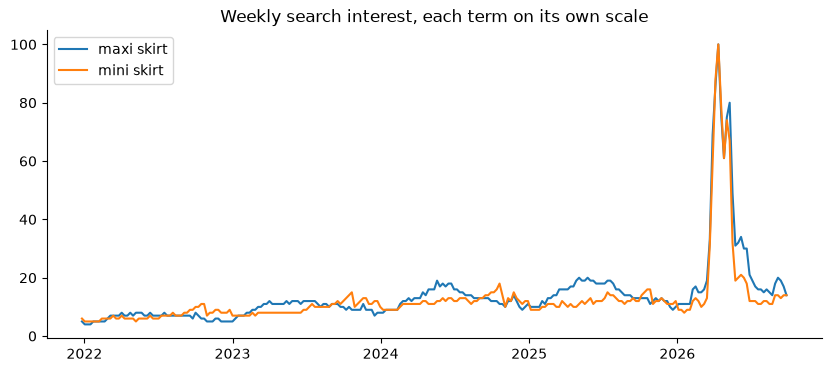

In [8]:
# Where is each term's peak, and how typical is it?
for term in TERMS:
    s = weekly.set_index("date")[term]
    print(f"\n{term}: peak week {s.idxmax().date()}, median {s.median()}")
    print(s.nlargest(5).to_string())

# Quick look at the shape
fig, ax = plt.subplots(figsize=(10, 4))
for term in TERMS:
    ax.plot(weekly["date"], weekly[term], label=term)
ax.set_title("Weekly search interest, each term on its own scale")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### 2.4 Check: is the April 2026 spike real?

Both terms peak in the same week (12 April 2026). Four comparison terms, pulled
separately over the same window, show whether the spike is specific to skirts:
- "skirt": does general skirt interest spike too?
- "jeans": did all clothing spike, or just skirts?
- "sofa": a non-clothing shopping term. If it spikes too, the spike runs across
  shopping searches generally, not just clothing.
- "pizza": an unrelated term. If it spikes the same week, the spike is a quirk in
  Google's data, not real interest.

skirt: peak week 2026-04-12, median 29.0, week of 2026-04-12: 100
jeans: peak week 2026-04-12, median 39.0, week of 2026-04-12: 100
sofa: peak week 2026-04-12, median 19.0, week of 2026-04-12: 100
pizza: peak week 2026-06-14, median 25.0, week of 2026-04-12: 23


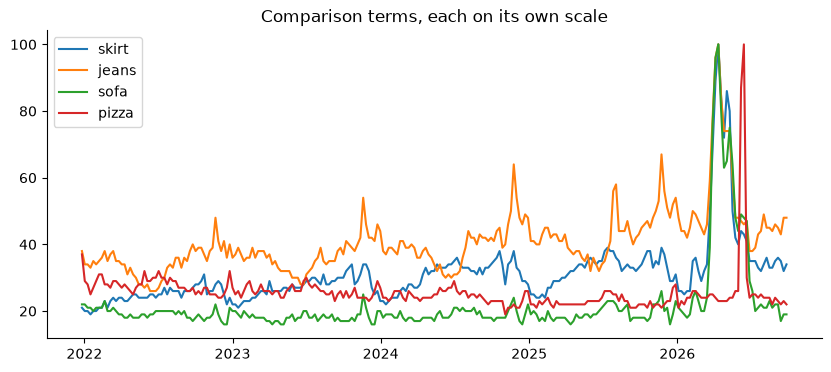

In [20]:
CONTROLS = ["skirt", "jeans", "sofa", "pizza"]

control_parts = []
for term in CONTROLS:
    time.sleep(60)  # stay under Google's rate limit
    df = pull_trends([term], timeframe="2022-01-01 2026-09-30")
    control_parts.append(df.set_index("date")[[term]])

controls = pd.concat(control_parts, axis=1)
controls["pull_date"] = PULL_DATE
controls.to_csv(RAW_DIR / "trends_weekly_controls.csv")

for term in CONTROLS:
    s = controls[term]
    print(f"{term}: peak week {s.idxmax().date()}, median {s.median()}, "
          f"week of 2026-04-12: {s.loc['2026-04-12']}")

fig, ax = plt.subplots(figsize=(10, 4))
for term in CONTROLS:
    ax.plot(controls.index, controls[term], label=term)
ax.set_title("Comparison terms, each on its own scale")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [10]:
print(monthly.set_index("date").loc["2026-02-01":"2026-07-01", TERMS])

            maxi skirt  mini skirt
date                              
2026-02-01           9          15
2026-03-01          16          25
2026-04-01          53         100
2026-05-01          38          62
2026-06-01          20          24
2026-07-01          11          14


**Result:** "skirt" and "jeans" both peak in the week of 12 April 2026; "pizza" does
not. The spike is clothing-wide, not specific to skirts, and not a fault across all of
Google. Cause unknown: a real surge in clothing searches, or a quirk in how Google
counted clothing searches. Either way, a rise in search volume that week says nothing
about hemlines, so the main test below uses the length mix instead.

### 2.5 Combined weekly pulls (shared scale)

Both terms in the same pull, so they share one 0 to 100 scale and can be compared.
Two windows:
- **Full window (Jan 2022 to Sep 2026):** includes April 2026.
- **Before the spike (Jan 2022 to Feb 2026):** without the April 2026 spike setting
  the scale, values in earlier years are larger and more precise. Used for the
  March 2025 test.

In [11]:
COMBINED_WINDOWS = {
    "trends_weekly_combined.csv": "2022-01-01 2026-09-30",
    "trends_weekly_prespike.csv": "2022-01-01 2026-02-28",
}

combined = {}
for fname, timeframe in COMBINED_WINDOWS.items():
    time.sleep(60)  # stay under Google's rate limit
    df = pull_trends(TERMS, timeframe=timeframe)
    df["pull_date"] = PULL_DATE
    df.to_csv(RAW_DIR / fname, index=False)
    combined[fname] = df
    print(f"{fname}: {df['date'].min().date()} to {df['date'].max().date()}, "
          f"{len(df)} rows, gap {df['date'].diff().dt.days.mode().iloc[0]} days")

weekly_both = combined["trends_weekly_combined.csv"]
weekly_pre = combined["trends_weekly_prespike.csv"]

trends_weekly_combined.csv: 2021-12-26 to 2026-09-27, 249 rows, gap 7.0 days
trends_weekly_prespike.csv: 2021-12-26 to 2026-02-22, 218 rows, gap 7.0 days


### 2.6 The length mix: what share of skirt searches are maxi?

The hemline index is about which lengths people choose, not how much they search for
skirts. So the main measure here is the mix: maxi skirt searches as a share of maxi
plus mini searches. A spike that lifts all clothing searches lifts both terms, so it
cancels out of the mix.

- **April 2026:** did the mix shift toward minis compared with the previous six months?
  Repeated for 2023 to 2026 to see what a normal April looks like.
- **March 2025:** did the mix shift toward maxis in the week containing 20 March,
  compared with the week before? Repeated for 2022 to 2025.

Shares are worked out from summed values over each period, which is steadier than
averaging weekly shares.

In [12]:
def period_share(frame, start, end):
    """Maxi skirt searches as a % of maxi + mini searches, summed over a period."""
    s = frame.loc[start:end, ["maxi skirt", "mini skirt"]].sum()
    return round(s["maxi skirt"] / s.sum() * 100, 1)

# April vs. previous six months (full combined pull, weeks assigned by their middle day)
weekly_both["mid"] = weekly_both["date"] + pd.Timedelta(days=3)
wb = weekly_both.set_index("mid").sort_index()

april_mix = pd.DataFrame([
    {"year": y,
     "maxi_share_prev_6m": period_share(wb, f"{y - 1}-10-01", f"{y}-03-31"),
     "maxi_share_april": period_share(wb, f"{y}-04-01", f"{y}-04-30")}
    for y in range(2023, 2027)
])
april_mix["shift_pts"] = (april_mix["maxi_share_april"] - april_mix["maxi_share_prev_6m"]).round(1)
print("Maxi share of skirt-length searches: April vs. previous six months")
print(april_mix.to_string(index=False))

# Week containing 20 March vs. the week before (pre-spike pull, finer values)
wp = weekly_pre.set_index("date").sort_index()
rows = []
for y in range(2022, 2026):
    day = pd.Timestamp(f"{y}-03-20")
    wk = wp.index[(wp.index <= day) & (wp.index + pd.Timedelta(days=7) > day)][0]
    prev_wk = wp.index[wp.index.get_loc(wk) - 1]
    rows.append({"year": y, "week_start": wk.date(),
                 "maxi_share_prev_week": period_share(wp, prev_wk, prev_wk),
                 "maxi_share_this_week": period_share(wp, wk, wk)})
march_mix = pd.DataFrame(rows)
march_mix["shift_pts"] = (march_mix["maxi_share_this_week"] - march_mix["maxi_share_prev_week"]).round(1)
print("\nMaxi share: week containing 20 March vs. the week before")
print(march_mix.to_string(index=False))

Maxi share of skirt-length searches: April vs. previous six months
 year  maxi_share_prev_6m  maxi_share_april  shift_pts
 2023                30.5              41.8       11.3
 2024                29.9              37.8        7.9
 2025                33.4              44.7       11.3
 2026                35.6              33.7       -1.9

Maxi share: week containing 20 March vs. the week before
 year week_start  maxi_share_prev_week  maxi_share_this_week  shift_pts
 2022 2022-03-20                  33.3                  35.3        2.0
 2023 2023-03-19                  38.9                  41.3        2.4
 2024 2024-03-17                  37.9                  35.8       -2.1
 2025 2025-03-16                  40.0                  43.0        3.0


### 2.7 Her comparison, by volume: miniskirt searches in April vs. the previous six months

This repeats her 11 April 2026 comparison as she described it: miniskirt popularity in
April vs. the average of the previous six months (October to March). It measures how
much people searched, not the length mix, so it's affected by the clothing-wide spike
in April 2026 (see 2.4). The fair test is the length mix in 2.6; this cell shows what
her method gives, and how a normal April compares.

- Weekly pull, "mini skirt" on its own scale (finer values): 2023 to 2026, the years
  with a full six months before April.
- Monthly pull (coarser, but 22 years): 2005 to 2026.
- Like-for-like: April 2026 vs. April 2025.

For reference, her figure was +78% for "April so far" as of 11 April 2026, from a mix
of posts, Google search and Pinterest search. This uses Google search only and the
full month of April, so the numbers won't match exactly.

Each week is assigned to the month its middle day falls in.

In [13]:
# Assign each week to a month by its middle day (week start + 3 days)
weekly["mid"] = weekly["date"] + pd.Timedelta(days=3)
w = weekly.set_index("mid").sort_index()

def april_vs_prev_six(series, year):
    """% change: April average vs. average of the previous October to March."""
    april = series[f"{year}-04-01":f"{year}-04-30"].mean()
    base = series[f"{year - 1}-10-01":f"{year}-03-31"].mean()
    return round((april / base - 1) * 100, 1)

# Weekly version: four recent years, "mini skirt" on its own scale
weekly_april = pd.DataFrame([
    {"year": y, "april_vs_prev_6m_pct": april_vs_prev_six(w["mini skirt"], y)}
    for y in range(2023, 2027)
])
print("Weekly pull (finer values):")
print(weekly_april.to_string(index=False))

# Like-for-like: April 2026 vs. April 2025
apr26 = w["mini skirt"]["2026-04-01":"2026-04-30"].mean()
apr25 = w["mini skirt"]["2025-04-01":"2025-04-30"].mean()
print(f"\nApril 2026 vs. April 2025: {round((apr26 / apr25 - 1) * 100, 1)}%")

# Monthly version: every year since 2005 (coarser values, see Limitations)
m = monthly.set_index("date")["mini skirt"]
rows = []
for y in range(2005, 2027):
    april = m.loc[f"{y}-04-01"]
    base = m.loc[f"{y - 1}-10-01":f"{y}-03-01"].mean()
    rows.append({"year": y, "april": april, "prev_6m_avg": round(base, 1),
                 "change_pct": round((april / base - 1) * 100, 1)})
monthly_april = pd.DataFrame(rows)

print("\nMonthly pull, 2005 to 2026:")
print(monthly_april.to_string(index=False))
print(f"\nYears where April beat the previous six months: "
      f"{(monthly_april['change_pct'] > 0).sum()} of {len(monthly_april)}")
print(f"Median April rise: {monthly_april['change_pct'].median()}%")

Weekly pull (finer values):
 year  april_vs_prev_6m_pct
 2023                  -1.9
 2024                   3.8
 2025                 -12.5
 2026                 522.7

April 2026 vs. April 2025: 646.2%

Monthly pull, 2005 to 2026:
 year  april  prev_6m_avg  change_pct
 2005      4          4.7       -14.3
 2006      5          4.3        15.4
 2007      4          3.7         9.1
 2008      4          4.2        -4.0
 2009      4          4.0         0.0
 2010      4          4.2        -4.0
 2011      4          4.3        -7.7
 2012      5          4.8         3.4
 2013      4          4.5       -11.1
 2014      5          5.0         0.0
 2015      4          4.7       -14.3
 2016      4          4.5       -11.1
 2017      5          4.7         7.1
 2018      4          5.2       -22.6
 2019      5          5.0         0.0
 2020      4          4.7       -14.3
 2021      5          5.5        -9.1
 2022      8          7.7         4.3
 2023     10         10.2        -1.6
 2024   

### 2.8 Her comparison, by volume: maxi skirt searches, week-on-week around 20 March

Her 20 March 2025 post compared maxi skirt popularity "one week ago vs. today" and
reported a 393% rise. This compares the week containing 20 March with the week
before, in every year from 2022 to 2025 and lists the biggest week-on-week rise each
spring (February to April).

It uses the pull that ends before the April 2026 anomaly (see 2.4), so the scale isn't
squashed and values are more precise. Both terms share that pull's scale; only
"maxi skirt" is used here.

Her exact number can't be reproduced from Google search alone (see Limitations). The
question is whether a mid-March jump in maxi skirt searches is unusual. Google labels
each week by the Sunday it starts on.

In [15]:
mx = weekly_pre.set_index("date")["maxi skirt"].sort_index()
wow = (mx.pct_change() * 100).round(1)  # week-on-week % change

def week_containing(day):
    """The week (labelled by its starting Sunday) that contains this day."""
    day = pd.Timestamp(day)
    return mx.index[(mx.index <= day) & (mx.index + pd.Timedelta(days=7) > day)][0]

# Week containing 20 March vs. the week before, 2022 to 2025
rows = []
for y in range(2022, 2026):
    wk = week_containing(f"{y}-03-20")
    rows.append({"year": y, "week_start": wk.date(), "prev_week": mx.shift(1)[wk],
                 "this_week": mx[wk], "wow_pct": wow[wk]})
march_wow = pd.DataFrame(rows)
print("Week containing 20 March vs. the week before:")
print(march_wow.to_string(index=False))

# Biggest week-on-week rise each spring
spring = wow[wow.index.month.isin([2, 3, 4])]
print("\nBiggest week-on-week rise, February to April:")
print(spring.groupby(spring.index.year).agg(["max", "idxmax"]).to_string())

# How unusual is the 2025 week? Compare with every week in the pull
wow_2025 = march_wow.loc[march_wow["year"] == 2025, "wow_pct"].iloc[0]
share_bigger = (wow.dropna() >= wow_2025).mean() * 100
print(f"\nWeeks with a rise at least as big as March 2025's ({wow_2025}%): "
      f"{share_bigger:.1f}% of all weeks, 2022 to Feb 2026")

Week containing 20 March vs. the week before:
 year week_start  prev_week  this_week  wow_pct
 2022 2022-03-20       18.0         18      0.0
 2023 2023-03-19       28.0         31     10.7
 2024 2024-03-17       36.0         34     -5.6
 2025 2025-03-16       38.0         43     13.2

Biggest week-on-week rise, February to April:
       max     idxmax
date                 
2022  14.3 2022-02-27
2023  14.3 2023-02-19
2024  20.0 2024-04-14
2025  18.5 2025-02-02
2026  41.9 2026-02-08

Weeks with a rise at least as big as March 2025's (13.2%): 7.4% of all weeks, 2022 to Feb 2026


### 2.9 The shape of a typical year

How much does the time of year alone move skirt interest? Each month is shown relative
to its own year's average (100 = an average month that year), then averaged across
years.

This uses a separate monthly pull for 2004 to 2025, ending before the April 2026
anomaly (see 2.4). In the full pull, the anomaly sets the 0 to 100 scale and squashes
earlier years to values of 4 or 5, too coarse to show a shape. Only years where a
term averaged at least 5 on this pull are included, to keep near-zero years from
distorting the shape.

In [16]:
import calendar

time.sleep(60)  # stay under Google's rate limit
monthly_pre = pull_trends(TERMS, timeframe="2004-01-01 2025-12-31")
monthly_pre["pull_date"] = PULL_DATE
monthly_pre.to_csv(RAW_DIR / "trends_monthly_prespike.csv", index=False)
print(f"{monthly_pre['date'].min().date()} to {monthly_pre['date'].max().date()}, "
      f"{len(monthly_pre)} rows")

mon = monthly_pre.set_index("date")[TERMS]
for term in TERMS:
    print(f"{term}: peak month {mon[term].idxmax().date()}")

# Each month relative to its own year's average, then averaged by calendar month
shape = {}
for term in TERMS:
    s = mon[term]
    yearly_mean = s.groupby(s.index.year).transform("mean")
    relative = s / yearly_mean * 100
    keep = yearly_mean >= 5
    years = sorted(set(s.index.year[keep]))
    print(f"{term}: {len(years)} years included ({years[0]} to {years[-1]})")
    shape[term] = relative[keep].groupby(relative[keep].index.month).mean().round(1)

shape = pd.DataFrame(shape)
shape.index = [calendar.month_abbr[m] for m in shape.index]
shape.index.name = "month"
shape.to_csv(PROCESSED_DIR / "trends_typical_year.csv")
print("\nTypical year (100 = an average month for that year):")
print(shape.to_string())

2004-01-01 to 2025-12-01, 264 rows
maxi skirt: peak month 2014-05-01
mini skirt: peak month 2024-10-01
maxi skirt: 15 years included (2011 to 2025)
mini skirt: 22 years included (2004 to 2025)

Typical year (100 = an average month for that year):
       maxi skirt  mini skirt
month                        
Jan          66.5        87.0
Feb          81.9        87.8
Mar         105.2        89.8
Apr         123.1        94.1
May         136.6        93.3
Jun         132.3        97.1
Jul         122.6       101.0
Aug         105.0       102.9
Sep          95.5       108.1
Oct          89.0       123.9
Nov          75.4       106.3
Dec          66.9       108.8


## 3. Plot

Exploratory charts only, to check the shapes before writing slide copy. Branded
versions are made in Canva.

1. **The typical year:** maxi vs. mini skirt interest by month (slide 6, the season).
2. **Maxi skirts, 2022 to Feb 2026:** weekly searches, with the week containing
   20 March marked each year (slide 6, March 2025 in context).
3. **The April 2026 anomaly:** skirts, jeans, sofa and pizza, each on its own scale
   (slide 6, the data blip).
4. **The long run, 2004 to 2025:** maxi and mini skirt searches, with the 2010 study's
   forecast window shaded (caption or LinkedIn only).

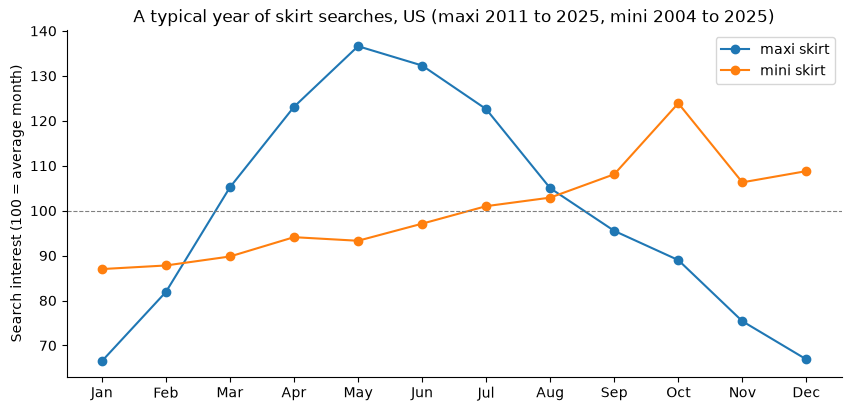

In [17]:
# Chart 1: the typical year (100 = an average month for that year)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(shape.index, shape["maxi skirt"], marker="o", label="maxi skirt")
ax.plot(shape.index, shape["mini skirt"], marker="o", label="mini skirt")
ax.axhline(100, color="grey", lw=0.8, ls="--")
ax.set_ylabel("Search interest (100 = average month)")
ax.set_title("A typical year of skirt searches, US (maxi 2011 to 2025, mini 2004 to 2025)")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

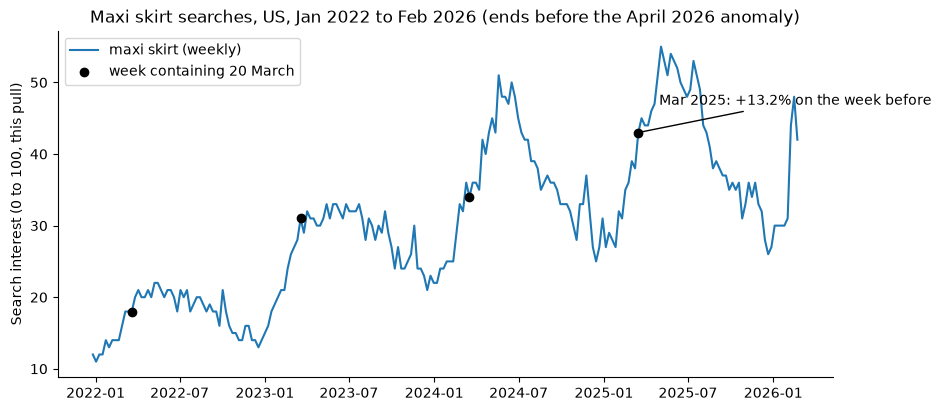

In [18]:
# Chart 2: maxi skirt searches by week, with the week containing 20 March marked
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(mx.index, mx.values, label="maxi skirt (weekly)")

march_weeks = pd.to_datetime(march_wow["week_start"])
ax.scatter(march_weeks, mx.loc[march_weeks], color="black", zorder=3,
           label="week containing 20 March")
wk25 = pd.Timestamp("2025-03-16")
ax.annotate("Mar 2025: +13.2% on the week before", xy=(wk25, mx.loc[wk25]),
            xytext=(15, 20), textcoords="offset points",
            arrowprops={"arrowstyle": "-", "color": "black"})

ax.set_ylabel("Search interest (0 to 100, this pull)")
ax.set_title("Maxi skirt searches, US, Jan 2022 to Feb 2026 (ends before the April 2026 anomaly)")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

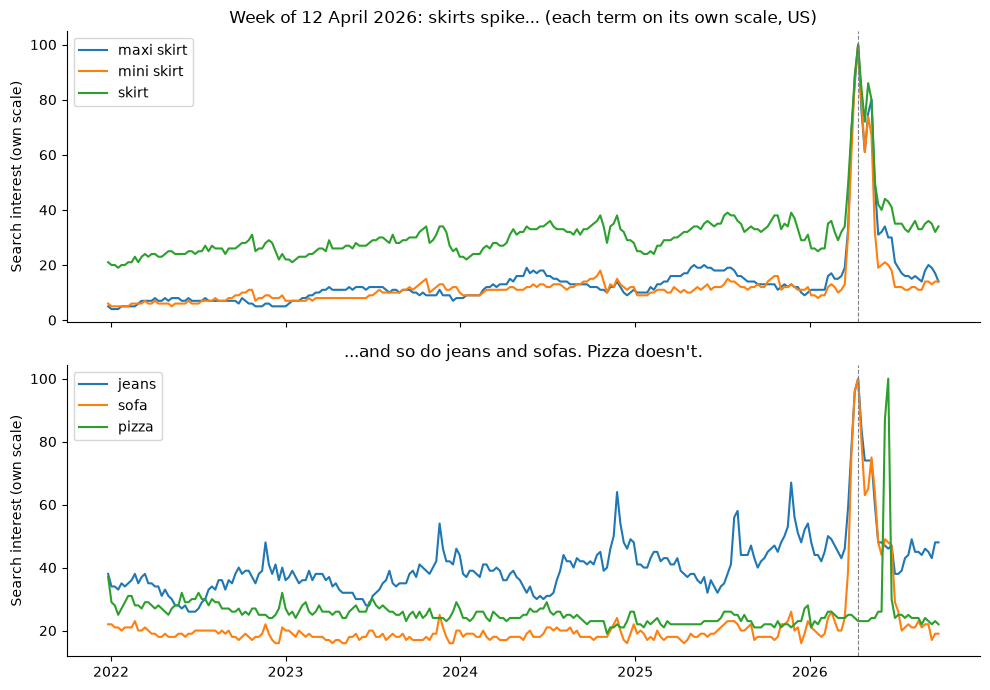

In [21]:
# Chart 3: the April 2026 anomaly, every term on its own 0-100 scale
controls_all = pd.read_csv(RAW_DIR / "trends_weekly_controls.csv",
                           index_col="date", parse_dates=["date"])

anomaly = (weekly.set_index("date")[["maxi skirt", "mini skirt"]]
           .join(controls_all[["skirt", "jeans", "sofa", "pizza"]]))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for term in ["maxi skirt", "mini skirt", "skirt"]:
    ax1.plot(anomaly.index, anomaly[term], label=term)
for term in ["jeans", "sofa", "pizza"]:
    ax2.plot(anomaly.index, anomaly[term], label=term)

for ax in (ax1, ax2):
    ax.axvline(pd.Timestamp("2026-04-12"), color="grey", ls="--", lw=0.8)
    ax.set_ylabel("Search interest (own scale)")
    ax.legend(loc="upper left")
    ax.spines[["top", "right"]].set_visible(False)
ax1.set_title("Week of 12 April 2026: skirts spike... (each term on its own scale, US)")
ax2.set_title("...and so do jeans and sofas. Pizza doesn't.")
plt.tight_layout()
plt.show()

In [23]:
# Data for the Canva version of slide 6 (each term on its own 0-100 scale)
canva = anomaly.loc["2025-10-01":"2026-07-31", ["mini skirt", "jeans", "sofa", "pizza"]]
canva.to_csv(PROCESSED_DIR / "slide6_anomaly_canva.csv")
print(f"{len(canva)} weeks")
print(canva.to_string())

43 weeks
            mini skirt  jeans  sofa  pizza
date                                      
2025-10-05          14     45    18     22
2025-10-12          15     46    18     22
2025-10-19          16     47    17     21
2025-10-26          16     45    18     23
2025-11-02          11     48    22     21
2025-11-09          12     50    22     22
2025-11-16          12     53    23     22
2025-11-23          13     67    26     21
2025-11-30          12     56    20     22
2025-12-07          11     51    21     23
2025-12-14          11     48    16     23
2025-12-21          11     52    19     27
2025-12-28          12     54    23     28
2026-01-04           9     48    21     21
2026-01-11           9     44    20     23
2026-01-18           8     44    19     22
2026-01-25           9     42    18     24
2026-02-01           9     45    19     24
2026-02-08          12     50    24     26
2026-02-15          13     49    26     26
2026-02-22          12     47    23     25
20

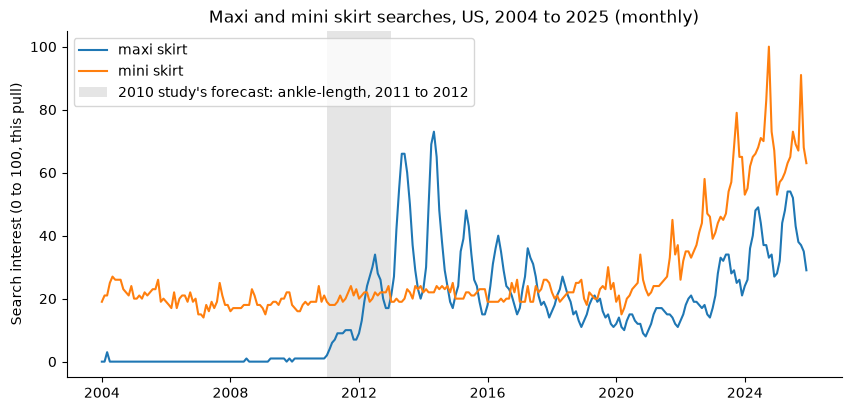

In [22]:
# Chart 4: the long run, with the 2010 study's forecast window shaded
fig, ax = plt.subplots(figsize=(10, 4.5))
for term in TERMS:
    ax.plot(mon.index, mon[term], label=term)
ax.axvspan(pd.Timestamp("2011-01-01"), pd.Timestamp("2012-12-31"),
           color="grey", alpha=0.2, lw=0, label="2010 study's forecast: ankle-length, 2011 to 2012")
ax.set_ylabel("Search interest (0 to 100, this pull)")
ax.set_title("Maxi and mini skirt searches, US, 2004 to 2025 (monthly)")
ax.legend(loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 4. Findings

### March 2025: maxi skirts (read as a coming recession)

- **Volume:** the week containing 20 March 2025 rose 13.2% on the week before (38 to 43).
  The same week in other years: 0.0% (2022), +10.7% (2023), -5.6% (2024).
- Each spring's biggest week-on-week rise was 14.3% (2022), 14.3% (2023), 20.0% (2024)
  and 18.5% (2025, early February). The March 2025 week was smaller than that year's
  biggest spring jump.
- A rise of 13.2% or more happens in 7.4% of weeks (about 1 in 13), January 2022 to
  February 2026.
- **Length mix:** maxi skirts' share of maxi + mini searches rose 3.0 points that week.
  Other years: +2.0, +2.4, -2.1. Within the normal range, and within rounding noise.
- **Typical year:** maxi skirt interest roughly doubles from January (66.5) to May
  (136.6), with March at 105.2 (100 = an average month; 2011 to 2025).
- **Conclusion:** in Google search data, March 2025 looks like an ordinary spring. Her
  393% came from a different blend of data, so it can't be reproduced or disproved here.

### April 2026: mini skirts (read as a sign the economy was doing well)

- **Volume:** mini skirt searches in April 2026 were 522.7% above the previous six
  months (weekly) and 646.2% above April 2025. In a normal April they don't rise:
  -1.9% (2023), +3.8% (2024), -12.5% (2025). In the monthly data, April beat the
  previous six months in only 7 of 22 years (median -2.8%).
- **Mini skirts are not a spring search:** in a typical year, April is 94.1 and the
  peak is October (123.9).
- **The anomaly:** in the week of 12 April 2026, "maxi skirt", "mini skirt", "skirt",
  "jeans" and "sofa" all peak at 100 on their own scales, with the same shape (a peak,
  a dip, a second bump in early May), while "pizza" stays at 24. Confirmed on
  trends.google.com on 2026-10-16. Jeans' April 2026 level beat its usual late-November
  peaks (about 54, 64 and 67 in 2023 to 2025).
- **Conclusion:** Google search data can't confirm a miniskirt-specific rise in April
  2026. April and May 2026 are excluded from conclusions about skirt length, including
  the April 2026 length mix. Her figure also used posts and Pinterest, which are not
  assessed here.
- Also noted, not used: maxi skirts rose 41.9% in the week of 8 February 2026, just
  before the anomaly. Unexplained.

### Normal springs tilt toward maxi skirts

- Maxi share of skirt-length searches, April vs. the previous six months: +11.3 points
  (2023), +7.9 (2024), +11.3 (2025).

### The long run (2004 to 2025)

- "Maxi skirt" is close to zero until about 2010, rises from 2011, and peaks in 2014.
  The 2010 study's forecast (ankle-length skirts around 2011 to 2012) lines up in timing,
  but the term itself was only just catching on, so this proves nothing.
- Since about 2021, both lengths have risen together: mini skirts from about 20 to peaks
  of 100 (October 2024) and 91 (October 2025), maxi skirts to about 54. Both lengths
  rising at once doesn't fit a single hemline reading.
- Mini skirt searches peak every October.

### For the slides

- Slide 3: both readings came in spring. Holds.
- Slide 6: two readings, two explanations, neither about the economy. March 2025 was
  the season (maxi searches roughly double from winter to May); April 2026 was a
  shopping-wide data blip (skirts, jeans and sofas spiked together; pizza didn't).
- Never set her 393% or 78% directly against these numbers: different data.
- Cite Google Trends with the pull date (2026-10-16); website screenshot in `sources.md`.